# Solutions to notebook 14: Partial differential equations: SymPy designs the method, SciPy runs it

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/14_partial_differential_equations.ipynb)

Worked solutions to the exercises at the end of [notebook 14](../notebooks/14_partial_differential_equations.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.sparse import diags, identity
from scipy.sparse.linalg import spsolve

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

x, t = sp.symbols("x t", nonnegative=True)
h = sp.symbols("h", positive=True)
f = sp.Function("f")

The exact series solution of the cooling slab from section 14.1 is needed in exercises 2 and 3.

In [2]:
def u_exact(x_values, time, terms=400):
    """Series solution for the cooling slab, summed over the first `terms` odd modes."""
    k = np.arange(1, 2 * terms, 2)[:, None]
    return (4 / (k * np.pi) * np.sin(k * np.pi * x_values) * np.exp(-(k * np.pi) ** 2 * time)).sum(axis=0)

## Exercise 1

Use the five-point weights of 14.2 to write a fourth-order formula for $f''(x)$, and find
the leading term of its truncation error. (It should be $-\dfrac{h^4}{90} f^{(6)}(x)$.)

In [3]:
offsets = [-2, -1, 0, 1, 2]
wide = sp.finite_diff_weights(2, offsets, 0)[2][-1]          # d2/dx2 on five points, as in 14.2
wide

[-1/12, 4/3, -5/2, 4/3, -1/12]

In [4]:
five_point = sum(weight * f(x + k * h) for weight, k in zip(wide, offsets)) / h**2
five_point

  5⋅f(x)   f(-2⋅h + x)   4⋅f(-h + x)   4⋅f(h + x)   f(2⋅h + x)
- ────── - ─────────── + ─────────── + ────────── - ──────────
    2          12             3            3            12    
──────────────────────────────────────────────────────────────
                               2                              
                              h                               

In [5]:
# Taylor-expand about x. Stopping the series at O(h^5) keeps exactly the leading error term.
truncation = sp.simplify(sp.series(five_point, h, 0, 5).doit().removeO() - f(x).diff(x, 2))
truncation

     6        
  4 d         
-h ⋅───(f(x)) 
      6       
    dx        
──────────────
      90      

In [6]:
# verify: the leading term stated in the exercise
assert sp.simplify(truncation + h**4 * f(x).diff(x, 6) / 90) == 0

# verify numerically on f = sin x at x = 1, where f'' = -sin 1 and the sixth derivative is -sin 1
formula = sp.lambdify((x, h), five_point.subs(f, sp.sin).doit(), "numpy")
steps = np.array([0.2, 0.1, 0.05])
errors = formula(1.0, steps) + np.sin(1.0)
order = np.log2(errors[:-1] / errors[1:])
print("error:          ", " ".join(f"{e:.3e}" for e in errors))
print("predicted error:", " ".join(f"{e:.3e}" for e in steps**4 * np.sin(1.0) / 90))
print("observed order: ", " ".join(f"{p:.2f}" for p in order))
assert np.all(np.abs(order - 4) < 0.05)
assert abs(errors[-1] / (steps[-1] ** 4 * np.sin(1.0) / 90) - 1) < 0.01

error:           1.491e-05 9.341e-07 5.842e-08
predicted error: 1.496e-05 9.350e-07 5.844e-08
observed order:  4.00 4.00


**Answer.**

$$f''(x) \approx \frac{-f(x-2h) + 16f(x-h) - 30f(x) + 16f(x+h) - f(x+2h)}{12h^2},$$

with truncation error $-\dfrac{h^4}{90} f^{(6)}(x)$ plus smaller terms. The formula is
fourth-order accurate: halving the grid spacing divides the error by 16, as the test on
$\sin x$ confirms.

## Exercise 2

Change the slab so that the face at $x = 1$ is insulated, $\partial u/\partial x = 0$, and
solve it by the method of lines for $t = 0.1$. Treat the wall value $u_N$ as an unknown and
use a mirror ("ghost") point, $u_{N+1} = u_{N-1}$. Check the result against the exact series
for a slab of thickness 2 cooled on both faces, which is the same problem by symmetry.

The unknowns are now $u_1,\dots,u_N$. At the wall the stencil reads
$(u_{N-1} - 2u_N + u_{N+1})/h^2$, and the ghost point turns it into $(2u_{N-1} - 2u_N)/h^2$:
the only change to the matrix of 14.3 is one extra row whose off-diagonal entry is 2.

In [7]:
def solve_insulated(N, t_end):
    """Cooling slab with u = 0 at x = 0 and an insulated face at x = 1; returns points 1..N."""
    grid = np.linspace(0, 1, N + 1)
    A = diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(N, N), format="lil")
    A[N - 1, N - 2] = 2.0                                   # ghost point: u_{N+1} = u_{N-1}
    A = A.tocsc() * N**2
    sol = solve_ivp(lambda _, u: A @ u, [0, t_end], np.ones(N), method="BDF", jac=A, rtol=1e-10, atol=1e-12)
    return grid[1:], sol.y[:, -1]

def u_insulated_exact(x_values, time):
    """The slab of thickness 2: lengths are halved and times divided by 4 in the units of u_exact."""
    return u_exact(np.asarray(x_values) / 2, time / 4)

**Verify** with a convergence study at $t = 0.1$, as in 14.3. The ghost-point treatment should
keep the second-order accuracy of the interior stencil.

In [8]:
N_values = np.array([10, 20, 40, 80, 160])
errors = np.array([np.abs(u - u_insulated_exact(xg, 0.1)).max() for xg, u in (solve_insulated(N, 0.1) for N in N_values)])
observed_order = np.log2(errors[:-1] / errors[1:])
print("max error:     ", " ".join(f"{e:.2e}" for e in errors))
print("observed order:", " ".join(f"{p:.2f}" for p in observed_order))
assert np.all(np.abs(observed_order[1:] - 2) < 0.15)
assert errors[-1] < 1e-4

max error:      2.42e-03 6.09e-04 1.52e-04 3.81e-05 9.53e-06
observed order: 1.99 2.00 2.00 2.00


At $t = 0.1$ the cooling has only just reached the insulated wall, so a later time is plotted as
well. The slope there must be zero at all times.

t = 0.1, N = 20: wall temperature 0.94870, exact 0.94931


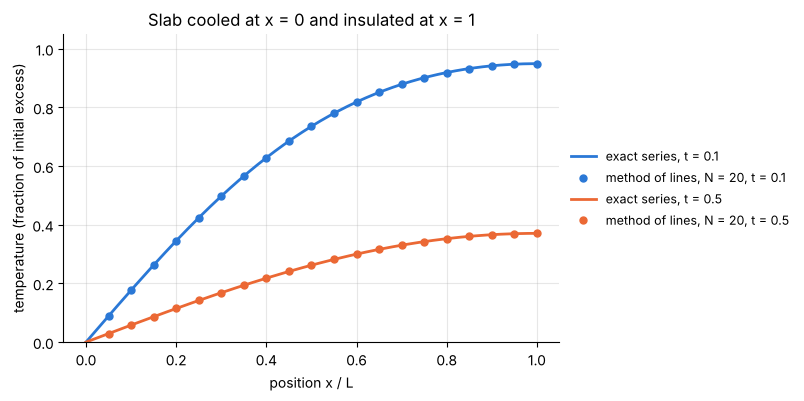

In [9]:
xs = np.linspace(0, 1, 201)
fig, ax = plt.subplots()
for time, colour in ((0.1, "#2a78d6"), (0.5, "#eb6834")):
    x_num, u_num = solve_insulated(20, time)
    assert np.abs(u_num - u_insulated_exact(x_num, time)).max() < 5e-3
    ax.plot(xs, u_insulated_exact(xs, time), color=colour, label=f"exact series, t = {time:g}")
    ax.plot(x_num, u_num, "o", color=colour, ms=5, label=f"method of lines, N = 20, t = {time:g}")
ax.set(xlabel="position x / L", ylabel="temperature (fraction of initial excess)", ylim=(0, 1.05),
       title="Slab cooled at x = 0 and insulated at x = 1")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)

x_num, u_num = solve_insulated(20, 0.1)
print(f"t = 0.1, N = 20: wall temperature {u_num[-1]:.5f}, exact {u_insulated_exact([1.0], 0.1)[0]:.5f}")

**Answer.** With the ghost point the wall row of the matrix becomes $(2u_{N-1} - 2u_N)/h^2$.
The numerical solution agrees with the series for a slab of thickness 2, which in the units of
14.1 is $u_{\mathrm{exact}}(x/2,\ t/4)$. The maximum error at $t = 0.1$ falls from
$2.4\times10^{-3}$ at $N = 10$ by a factor of four for each halving of $h$: second order. At
$t = 0.1$ the insulated wall is still at 0.949 of its initial excess temperature.

## Exercise 3

The Crank–Nicolson scheme averages the explicit and implicit right-hand sides. Derive its
amplification factor and show that $|g| \le 1$ for every $r$.

In [10]:
g, r, theta = sp.symbols("g r theta", real=True)

def fourier_mode(step, node):
    return g**step * sp.exp(sp.I * node * theta)

def second_difference(step):
    return fourier_mode(step, 1) - 2 * fourier_mode(step, 0) + fourier_mode(step, -1)

crank_nicolson = sp.Eq(fourier_mode(1, 0), fourier_mode(0, 0) + r / 2 * (second_difference(0) + second_difference(1)))
g_raw = sp.solve(crank_nicolson, g)[0]
g_raw

     2⋅ⅈ⋅θ        ⅈ⋅θ          ⅈ⋅θ
- r⋅ℯ      + 2⋅r⋅ℯ    - r - 2⋅ℯ   
──────────────────────────────────
    2⋅ⅈ⋅θ        ⅈ⋅θ          ⅈ⋅θ 
 r⋅ℯ      - 2⋅r⋅ℯ    + r - 2⋅ℯ    

The numerator and the denominator are each complex, but their ratio is real. Multiplying both
by $e^{-i\theta}$ before rewriting in cosines makes that visible.

In [11]:
numerator, denominator = sp.fraction(sp.together(g_raw))
to_cosines = lambda part: sp.simplify(sp.expand(part * sp.exp(-sp.I * theta)).rewrite(sp.cos))
g_cn = sp.cancel(to_cosines(numerator) / to_cosines(denominator))
g_cn

-r⋅cos(θ) + r - 1
─────────────────
r⋅cos(θ) - r - 1 

In [12]:
# the same thing in terms of sin²(θ/2), the form used in 14.4
assert sp.simplify((g_cn - g_raw).rewrite(sp.exp)) == 0     # nothing was lost in the rewriting
assert sp.simplify(g_cn - (1 - 2 * r * sp.sin(theta / 2) ** 2) / (1 + 2 * r * sp.sin(theta / 2) ** 2)) == 0

Write $q = 2r\sin^2(\theta/2)$, which is never negative. Then $g = (1 - q)/(1 + q)$ and $1 - g^2$
shows directly whether $|g| \le 1$.

In [13]:
q = sp.symbols("q", nonnegative=True)
margin = sp.factor(1 - ((1 - q) / (1 + q)) ** 2)
assert margin.is_nonnegative                                # so g² ≤ 1 for every q ≥ 0
assert sp.limit((1 - q) / (1 + q), q, sp.oo) == -1          # |g| approaches 1 but never reaches it
margin

  4⋅q   
────────
       2
(q + 1) 

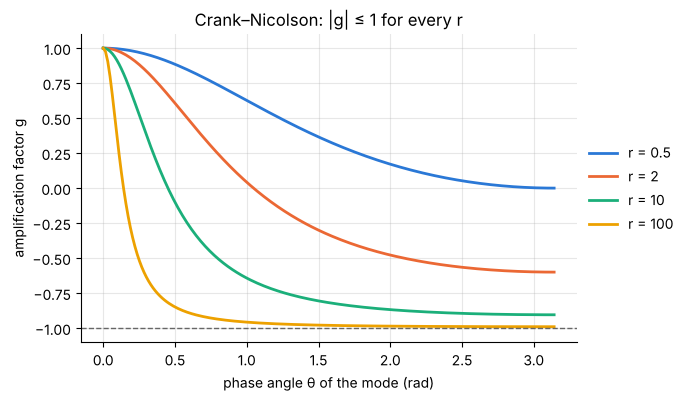

In [14]:
# verify numerically: scan a wide range of r and every mode
g_cn_fun = sp.lambdify((r, theta), g_cn, "numpy")
r_scan, theta_scan = np.meshgrid(np.logspace(-3, 6, 200), np.linspace(0, np.pi, 181))
assert np.abs(g_cn_fun(r_scan, theta_scan)).max() <= 1

thetas = np.linspace(0, np.pi, 200)
fig, ax = plt.subplots()
for r_value in (0.5, 2, 10, 100):
    ax.plot(thetas, g_cn_fun(r_value, thetas), label=f"r = {r_value:g}")
ax.axhline(-1, color="0.4", lw=1, ls="--")
ax.set(xlabel="phase angle θ of the mode (rad)", ylabel="amplification factor g", ylim=(-1.1, 1.1),
       title="Crank–Nicolson: |g| ≤ 1 for every r")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

A direct test: march the cooling slab of 14.4 with $r = 2$, four times the explicit limit. Each
step now needs the solution of a tridiagonal system.

In [15]:
def crank_nicolson_march(r_value, N=20, t_end=0.1):
    D = diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(N - 1, N - 1), format="csc")
    left = (identity(N - 1) - r_value / 2 * D).tocsc()
    right = (identity(N - 1) + r_value / 2 * D).tocsc()
    u = np.ones(N - 1)
    for _ in range(round(t_end * N**2 / r_value)):
        u = spsolve(left, right @ u)
    return np.linspace(0, 1, N + 1)[1:-1], u

x_cn, u_cn = crank_nicolson_march(2.0)
error_cn = np.abs(u_cn - u_exact(x_cn, 0.1)).max()
print(f"r = 2: largest value {u_cn.max():.4f}, maximum error against the exact series {error_cn:.1e}")
assert u_cn.max() < 1 and error_cn < 2e-3                   # the explicit scheme failed already at r = 0.52

r = 2: largest value 0.4744, maximum error against the exact series 1.1e-04


**Answer.**

$$g = \frac{1 - 2r\sin^2(\theta/2)}{1 + 2r\sin^2(\theta/2)} = \frac{1-q}{1+q},\qquad
1 - g^2 = \frac{4q}{(1+q)^2} \ge 0 ,$$

so $|g| \le 1$ for every $r \ge 0$ and every mode: the scheme is unconditionally stable. For
large $r$ the sawtooth modes have $g$ close to $-1$. They do not grow, but they decay slowly and
change sign every step, which is why Crank–Nicolson can show small oscillations after a sudden
change when the time step is very large.

## Exercise 4

A fin loses heat from its surface: $\dfrac{\partial\theta}{\partial t} =
\dfrac{\partial^2\theta}{\partial x^2} - m^2\theta$ with $\theta(0,t) = 1$, an insulated tip
at $x = 1$, $\theta(x,0) = 0$ and $m = 2$. Integrate to $t = 3$ and show that the solution has
reached the steady profile $\cosh m(1-x)/\cosh m$ of notebook 6.

Two things change compared with exercise 2. The surface loss adds $-m^2$ on the diagonal, and
the base value $\theta_0 = 1$ is known, so it moves to the right-hand side as a constant source
$1/h^2$ in the first equation.

In [16]:
m_fin = 2.0

def fin_system(N):
    A = diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(N, N), format="lil")
    A[N - 1, N - 2] = 2.0                                   # insulated tip, ghost point
    A = (A.tocsc() * N**2 - m_fin**2 * identity(N)).tocsc()
    base = np.zeros(N)
    base[0] = N**2                                          # from the known base temperature θ_0 = 1
    return np.linspace(0, 1, N + 1)[1:], A, base

def solve_fin(N, times):
    grid, A, base = fin_system(N)
    sol = solve_ivp(lambda _, th: A @ th + base, [0, times[-1]], np.zeros(N), method="BDF", jac=A,
                    t_eval=times, rtol=1e-10, atol=1e-12)
    return grid, sol.y

def steady_fin(x_values):
    return np.cosh(m_fin * (1 - x_values)) / np.cosh(m_fin)

In [17]:
# verify the steady profile itself with SymPy: equation, base temperature and insulated tip
m_sym = sp.symbols("m", positive=True)
steady_sym = sp.cosh(m_sym * (1 - x)) / sp.cosh(m_sym)
assert sp.simplify(steady_sym.diff(x, 2) - m_sym**2 * steady_sym) == 0
assert steady_sym.subs(x, 0) == 1 and steady_sym.diff(x).subs(x, 1) == 0

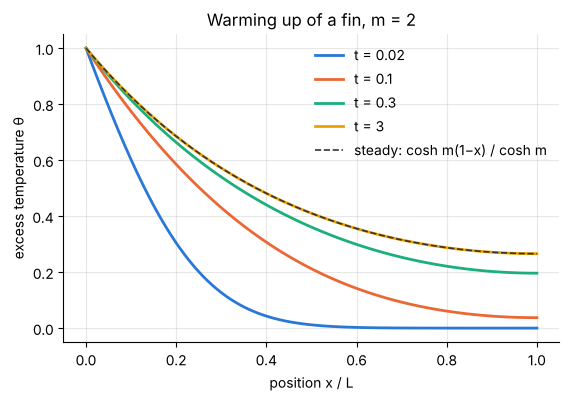

In [18]:
plot_times = [0.02, 0.1, 0.3, 3.0]
x_fin, theta_fin = solve_fin(100, plot_times)

fig, ax = plt.subplots()
for column, time in enumerate(plot_times):
    ax.plot(np.concatenate(([0], x_fin)), np.concatenate(([1], theta_fin[:, column])), label=f"t = {time:g}")
ax.plot(xs, steady_fin(xs), color="0.2", lw=1.2, ls="--", label="steady: cosh m(1−x) / cosh m")
ax.set(xlabel="position x / L", ylabel="excess temperature θ", title="Warming up of a fin, m = 2")
ax.legend(frameon=False, loc="upper right");

**Verify.** The difference from the steady profile at $t = 3$ has two parts. One is the spatial
error of the stencil, which is of order $h^2$ and has nothing to do with time. The other is how
far the time integration still is from its own steady state, found by solving the discrete
equations $\mathbf{A}\boldsymbol\theta + \mathbf{b} = 0$ directly. Separation of variables predicts
the second part: the slowest mode is $\sin(\pi x/2)\,e^{-(m^2 + \pi^2/4)t}$.

In [19]:
errors_fin = []
for N in (25, 50, 100):
    grid, A, base = fin_system(N)
    theta_end = solve_fin(N, [3.0])[1][:, -1]
    discrete_steady = spsolve(A, -base)
    errors_fin.append(np.abs(theta_end - steady_fin(grid)).max())
    assert np.abs(theta_end - discrete_steady).max() < 1e-7              # time: steady state reached
fin_order = np.log2(np.array(errors_fin[:-1]) / np.array(errors_fin[1:]))
slowest = np.exp(-(m_fin**2 + np.pi**2 / 4) * 3)

print("distance from cosh profile at t = 3:", " ".join(f"{e:.2e}" for e in errors_fin), "  (N = 25, 50, 100)")
print("observed order:", " ".join(f"{p:.2f}" for p in fin_order))
print(f"distance from the discrete steady state, N = 100: {np.abs(theta_end - discrete_steady).max():.1e}")
print(f"slowest mode at t = 3: exp(-(m² + π²/4) t) = {slowest:.1e}")
print(f"tip temperature: {theta_end[-1]:.5f}   exact 1/cosh 2 = {1 / np.cosh(2):.5f}")
assert np.all(np.abs(fin_order - 2) < 0.1) and errors_fin[-1] < 1e-4

distance from cosh profile at t = 3: 1.37e-04 3.42e-05 8.54e-06   (N = 25, 50, 100)
observed order: 2.00 2.00
distance from the discrete steady state, N = 100: 1.8e-09
slowest mode at t = 3: exp(-(m² + π²/4) t) = 3.7e-09
tip temperature: 0.26581   exact 1/cosh 2 = 0.26580


**Answer.** At $t = 3$ the numerical solution is within $2\times10^{-9}$ of the steady state of the
discrete equations, as expected from the slowest mode, which has decayed to
$e^{-(m^2+\pi^2/4)\,3} \approx 4\times10^{-9}$. It differs from
$\cosh m(1-x)/\cosh m$ by $8.5\times10^{-6}$ for $N = 100$, and that difference falls as $h^2$:
it is the spatial truncation error, not unfinished warming up. The tip temperature is
$1/\cosh 2 = 0.2658$. The plot shows that the profile is already close to steady by $t = 0.3$.

## Exercise 5

Verify a method-of-lines code for the viscous Burgers equation
$\dfrac{\partial u}{\partial t} + u\dfrac{\partial u}{\partial x} = \nu\dfrac{\partial^2 u}{\partial x^2}$
with $\nu = 0.1$, using the manufactured solution $u_m = e^{-t}\sin(\pi x)$ and central
differences. Confirm second-order convergence.

Follow 14.5. The manufactured solution does not satisfy the equation, so SymPy computes the
source term that makes it do so.

In [20]:
nu = sp.Rational(1, 10)
u_m = sp.exp(-t) * sp.sin(sp.pi * x)                    # zero at both walls
source = sp.simplify(u_m.diff(t) + u_m * u_m.diff(x) - nu * u_m.diff(x, 2))
source

⎛⎛       2⎞  t                ⎞  -2⋅t         
⎝⎝-10 + π ⎠⋅ℯ  + 10⋅π⋅cos(π⋅x)⎠⋅ℯ    ⋅sin(π⋅x)
──────────────────────────────────────────────
                      10                      

In [21]:
u_m_fun = sp.lambdify((x, t), u_m, "numpy")
source_fun = sp.lambdify((x, t), source, "numpy")

def solve_burgers(N, t_end, with_source=True, initial=u_m_fun):
    """Central differences for both the convection and the diffusion term; u = 0 at both walls."""
    inner = np.linspace(0, 1, N + 1)[1:-1]

    def rate(time, u_inner):
        u = np.concatenate(([0.0], u_inner, [0.0]))
        convection = u[1:-1] * (u[2:] - u[:-2]) * N / 2
        diffusion = float(nu) * (u[2:] - 2 * u[1:-1] + u[:-2]) * N**2
        return -convection + diffusion + (source_fun(inner, time) if with_source else 0.0)

    sol = solve_ivp(rate, [0, t_end], initial(inner, 0), method="BDF", rtol=1e-10, atol=1e-12)
    return inner, sol.y[:, -1]

N_mms = np.array([10, 20, 40, 80, 160])
mms_errors = np.array([np.abs(u - u_m_fun(xg, 0.5)).max() for xg, u in (solve_burgers(N, 0.5) for N in N_mms)])
mms_order = np.log2(mms_errors[:-1] / mms_errors[1:])
print("max error:     ", " ".join(f"{e:.2e}" for e in mms_errors))
print("observed order:", " ".join(f"{p:.2f}" for p in mms_order))
assert np.all(np.abs(mms_order - 2) < 0.1)

max error:      4.35e-03 1.08e-03 2.70e-04 6.74e-05 1.69e-05
observed order: 2.01 2.00 2.00 2.00


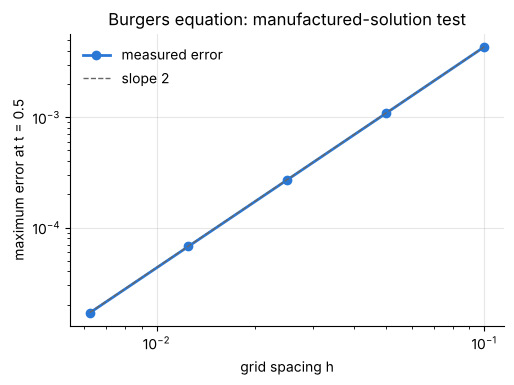

In [22]:
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.loglog(1 / N_mms, mms_errors, "o-", label="measured error")
ax.loglog(1 / N_mms, mms_errors[0] * (N_mms[0] / N_mms) ** 2, "--", color="0.4", lw=1, label="slope 2")
ax.set(xlabel="grid spacing h", ylabel="maximum error at t = 0.5", title="Burgers equation: manufactured-solution test")
ax.legend(frameon=False);

The code is verified, so it can be trusted on the problem without a source term. Starting from
$\sin(\pi x)$, convection carries the hump to the right and steepens its front, while diffusion
makes it decay.

peak 0.579 at x = 0.675


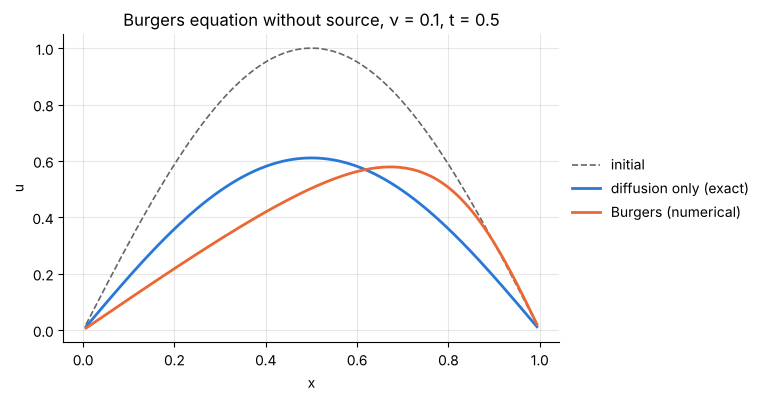

In [23]:
x_b, u_b = solve_burgers(160, 0.5, with_source=False)
x_b2, u_b2 = solve_burgers(320, 0.5, with_source=False)
assert np.abs(u_b - u_b2[1::2]).max() < 1e-3             # the answer no longer depends on the grid
assert x_b[u_b.argmax()] > 0.5                           # the peak has moved downstream

fig, ax = plt.subplots()
ax.plot(x_b, np.sin(np.pi * x_b), color="0.4", lw=1.2, ls="--", label="initial")
ax.plot(x_b, np.exp(-0.1 * np.pi**2 * 0.5) * np.sin(np.pi * x_b), label="diffusion only (exact)")
ax.plot(x_b, u_b, label="Burgers (numerical)")
ax.set(xlabel="x", ylabel="u", title="Burgers equation without source, ν = 0.1, t = 0.5")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
print(f"peak {u_b.max():.3f} at x = {x_b[u_b.argmax()]:.3f}")

**Answer.** The source term is
$s = e^{-t}\sin(\pi x)\left[\nu\pi^2 - 1 + \pi e^{-t}\cos(\pi x)\right]$ with $\nu = 0.1$.
With it, the maximum error at $t = 0.5$ falls by a factor of four each time the grid spacing is
halved, so the observed order is 2: the central-difference discretization of both the
convection term and the diffusion term is correct.